<a href="https://colab.research.google.com/github/abarg12/database_demos/blob/main/GraphDB_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# T5: Knowledge Graphs and Graph Databases
**ECE 501c Flipped Classroom Demo, Team 5**

In this notebook we build one small knowledge graph and look at it three ways:

1. As a list of **subject, relation, object** facts
2. As an **RDF graph**, queried with **SPARQL** (using `rdflib`)
3. As a **property graph** stored in a real graph database, queried with **Cypher** (using Kùzu, an embedded graph DB that runs inside Colab with no server)

Then we ask the same question in **SQL** to compare graph and relational databases, and finish with two applications: dependency analysis and collaborator recommendations.

Running question for the whole demo: **"Who shares a project with Alice?"**

| Section | Topic |
|---|---|
| 0 | Setup |
| 1 | Facts as triples |
| 2 | Visualizing the graph |
| 3 | RDF and SPARQL |
| 4 | Property graph and Cypher |
| 5 | Graph DB vs relational DB |
| 6 | Applications |
| 7 | Questions for the class |

## 0. Setup
We install two libraries. `rdflib` handles RDF triples and SPARQL. `kuzu` is an embedded graph database that uses Cypher, the same query language as Neo4j.

In [ ]:
!pip install -q rdflib kuzu==0.11.3

In [ ]:
# pyvis installation removed

In [ ]:
import glob
import os
import sqlite3

import kuzu
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from rdflib import RDF, RDFS, Graph, Literal, Namespace

print("kuzu version:", kuzu.__version__)

kuzu version: 0.11.3


## 1. Knowledge Graph Facts as Triples

A knowledge graph stores entities and the relationships between them.

* **Entities:** Nodes in our graph (e.g., Alice, Atlas)
* **Relationships:** Edges connecting entities
* **Format:** The simplest representation is a list of facts written as `(Subject, Relation, Object)`.

*Note: We are using the five facts from the slides, plus a few extras (Dave, Core, and dependencies) to make traversals more interesting. We also track the **source** system for each fact, which is crucial for real-world data integration.*

In [ ]:
works_on_facts = [
    # (person, project, role, source)
    ("Alice", "Atlas",  "lead",      "hr_system"),
    ("Bob",   "Atlas",  "developer", "hr_system"),
    ("Alice", "Beacon", "reviewer",  "project_tracker"),
    ("Bob",   "Beacon", "developer", "project_tracker"),
    ("Carol", "Beacon", "lead",      "project_tracker"),
    ("Dave",  "Core",   "lead",      "project_tracker"),
]

depends_on_facts = [
    # (project, depends on project)
    ("Beacon", "Atlas"),
    ("Atlas",  "Core"),
]

people = ["Alice", "Bob", "Carol", "Dave"]
projects = ["Atlas", "Beacon", "Core"]

triples_table = pd.DataFrame(
    [(person, "WORKS_ON", project) for person, project, _, _ in works_on_facts]
    + [(project, "DEPENDS_ON", dependency) for project, dependency in depends_on_facts],
    columns=["Subject", "Relation", "Object"],
)
triples_table

,Subject,Relation,Object
0,Alice,WORKS_ON,Atlas
1,Bob,WORKS_ON,Atlas
2,Alice,WORKS_ON,Beacon
3,Bob,WORKS_ON,Beacon
4,Carol,WORKS_ON,Beacon
5,Dave,WORKS_ON,Core
6,Beacon,DEPENDS_ON,Atlas
7,Atlas,DEPENDS_ON,Core


Notice that **direction matters**. `Alice WORKS_ON Atlas` is a true fact, but `Atlas WORKS_ON Alice` makes no sense.

## 2. Visualizing the Graph

Drawing the graph makes its structure intuitive:
* 🔵 **Blue Nodes** = People
* 🟠 **Orange Nodes** = Projects

**Demo Question:** *Who shares a project with Alice?*
* **Visually:** Follow Alice's outgoing arrows to her projects, then trace the incoming arrows back to find her coworkers.

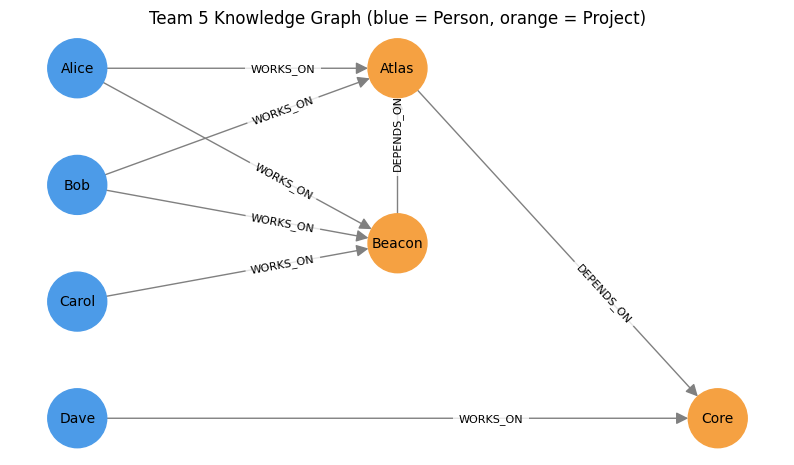

In [ ]:
knowledge_graph = nx.DiGraph()

for person in people:
    knowledge_graph.add_node(person, node_type="Person")
for project in projects:
    knowledge_graph.add_node(project, node_type="Project")

for person, project, role, source in works_on_facts:
    knowledge_graph.add_edge(person, project, relation="WORKS_ON")
for project, dependency in depends_on_facts:
    knowledge_graph.add_edge(project, dependency, relation="DEPENDS_ON")

node_positions = {
    "Alice": (0, 3), "Bob": (0, 2), "Carol": (0, 1), "Dave": (0, 0),
    "Atlas": (3, 3), "Beacon": (3, 1.5), "Core": (6, 0),
}
node_colors = [
    "#4C9BE8" if knowledge_graph.nodes[node]["node_type"] == "Person" else "#F5A142"
    for node in knowledge_graph.nodes
]
edge_labels = nx.get_edge_attributes(knowledge_graph, "relation")

plt.figure(figsize=(10, 5.5))
nx.draw_networkx(
    knowledge_graph, node_positions, node_color=node_colors, node_size=1800,
    font_size=10, arrowsize=18, edge_color="gray",
)
nx.draw_networkx_edge_labels(
    knowledge_graph, node_positions, edge_labels=edge_labels, font_size=8, label_pos=0.65,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8},
)
plt.title("Team 5 Knowledge Graph (blue = Person, orange = Project)")
plt.axis("off")
plt.show()

## 3. RDF Graph and SPARQL

**Resource Description Framework (RDF)**:
* Every fact is stored as a triple.
* Entities and predicates use **IRIs** (globally unique identifiers, like URLs). This enables linking knowledge graphs across different organizations.

**RDFS Schema**:
We've added a small schema to define our graph's structure:
* **Classes:** `Person` and `Project`
* **Properties:** `worksOn` (Domain: Person $\rightarrow$ Range: Project)

In [ ]:
EX = Namespace("http://example.org/team5/")

rdf_graph = Graph()
rdf_graph.bind("ex", EX)

# Schema (RDFS): classes and the meaning of each relation
rdf_graph.add((EX.Person, RDF.type, RDFS.Class))
rdf_graph.add((EX.Project, RDF.type, RDFS.Class))
rdf_graph.add((EX.worksOn, RDFS.domain, EX.Person))
rdf_graph.add((EX.worksOn, RDFS.range, EX.Project))
rdf_graph.add((EX.dependsOn, RDFS.domain, EX.Project))
rdf_graph.add((EX.dependsOn, RDFS.range, EX.Project))

# Entities: stable IRIs plus a human readable label
for person in people:
    rdf_graph.add((EX[person.lower()], RDF.type, EX.Person))
    rdf_graph.add((EX[person.lower()], RDFS.label, Literal(person)))
for project in projects:
    rdf_graph.add((EX[project.lower()], RDF.type, EX.Project))
    rdf_graph.add((EX[project.lower()], RDFS.label, Literal(project)))

# Facts
for person, project, role, source in works_on_facts:
    rdf_graph.add((EX[person.lower()], EX.worksOn, EX[project.lower()]))
for project, dependency in depends_on_facts:
    rdf_graph.add((EX[project.lower()], EX.dependsOn, EX[dependency.lower()]))

print("Number of triples:", len(rdf_graph))

Number of triples: 28


RDF is a standard exchange format. Here is the graph written in **Turtle**, a readable RDF syntax. Any RDF tool can load this file.

In [ ]:
print(rdf_graph.serialize(format="turtle"))

@prefix ex: <http://example.org/team5/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .

ex:Person a rdfs:Class .

ex:Project a rdfs:Class .

ex:alice a ex:Person ;
    rdfs:label "Alice" ;
    ex:worksOn ex:atlas,
        ex:beacon .

ex:bob a ex:Person ;
    rdfs:label "Bob" ;
    ex:worksOn ex:atlas,
        ex:beacon .

ex:carol a ex:Person ;
    rdfs:label "Carol" ;
    ex:worksOn ex:beacon .

ex:dave a ex:Person ;
    rdfs:label "Dave" ;
    ex:worksOn ex:core .

ex:dependsOn rdfs:domain ex:Project ;
    rdfs:range ex:Project .

ex:worksOn rdfs:domain ex:Person ;
    rdfs:range ex:Project .

ex:core a ex:Project ;
    rdfs:label "Core" .

ex:atlas a ex:Project ;
    rdfs:label "Atlas" ;
    ex:dependsOn ex:core .

ex:beacon a ex:Project ;
    rdfs:label "Beacon" ;
    ex:dependsOn ex:atlas .




### SPARQL: Who shares a project with Alice?
SPARQL matches **graph patterns**. Variables start with `?`. The pattern below says: Alice works on some `?project`, and some `?coworker` also works on that same `?project`. `FILTER` removes Alice herself and `DISTINCT` removes repeats (Bob shares two projects with Alice).

In [ ]:
shared_project_query = '''
PREFIX ex:   <http://example.org/team5/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?coworkerName
WHERE {
    ex:alice   ex:worksOn ?project .
    ?coworker  ex:worksOn ?project .
    ?coworker  rdfs:label ?coworkerName .
    FILTER (?coworker != ex:alice)
}
ORDER BY ?coworkerName
'''

for result_row in rdf_graph.query(shared_project_query):
    print(result_row.coworkerName)

Bob
Carol


### SPARQL with aggregation: how many people work on each project?

In [ ]:
team_size_query = '''
PREFIX ex:   <http://example.org/team5/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?projectName (COUNT(?person) AS ?teamSize)
WHERE {
    ?person  ex:worksOn ?project .
    ?project rdfs:label ?projectName .
}
GROUP BY ?projectName
ORDER BY DESC(?teamSize)
'''

pd.DataFrame(
    [(str(row.projectName), int(row.teamSize)) for row in rdf_graph.query(team_size_query)],
    columns=["Project", "Team Size"],
)

,Project,Team Size
0,Beacon,3
1,Atlas,2
2,Core,1


### 3.1 Visualizing the RDF Graph
We can write a helper function that extracts all triples from our `rdf_graph` and loads them into `networkx` for plotting.

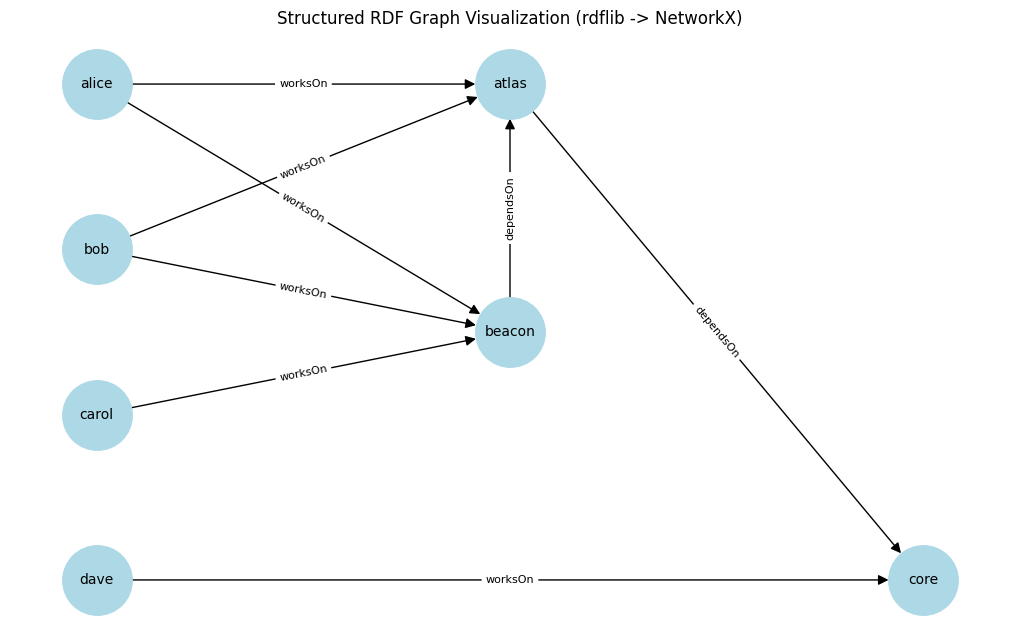

In [ ]:
!pip install -q rdflib
import matplotlib.pyplot as plt
import networkx as nx
from rdflib import RDF, RDFS, Graph, Literal, Namespace

# Recreate data and rdflib graph to make this cell self-contained
works_on_facts = [
    ("Alice", "Atlas",  "lead",      "hr_system"),
    ("Bob",   "Atlas",  "developer", "hr_system"),
    ("Alice", "Beacon", "reviewer",  "project_tracker"),
    ("Bob",   "Beacon", "developer", "project_tracker"),
    ("Carol", "Beacon", "lead",      "project_tracker"),
    ("Dave",  "Core",   "lead",      "project_tracker"),
]
depends_on_facts = [
    ("Beacon", "Atlas"),
    ("Atlas",  "Core"),
]
people = ["Alice", "Bob", "Carol", "Dave"]
projects = ["Atlas", "Beacon", "Core"]

EX = Namespace("http://example.org/team5/")
rdf_graph = Graph()
rdf_graph.bind("ex", EX)

for person in people:
    rdf_graph.add((EX[person.lower()], RDF.type, EX.Person))
    rdf_graph.add((EX[person.lower()], RDFS.label, Literal(person)))
for project in projects:
    rdf_graph.add((EX[project.lower()], RDF.type, EX.Project))
    rdf_graph.add((EX[project.lower()], RDFS.label, Literal(project)))
for person, project, role, source in works_on_facts:
    rdf_graph.add((EX[person.lower()], EX.worksOn, EX[project.lower()]))
for project, dependency in depends_on_facts:
    rdf_graph.add((EX[project.lower()], EX.dependsOn, EX[dependency.lower()]))

def visualize_rdflib_graph(rdf_g):
    G = nx.DiGraph()
    for s, p, o in rdf_g:
        s_label = s.split('/')[-1]
        o_label = o.split('/')[-1]
        p_label = p.split('/')[-1]
        # FIXED: Added `str(p)` to the filter so we ignore schema edges like RDFS.label
        if not any(x in str(s) or x in str(p) or x in str(o) for x in ['rdf-schema', '22-rdf-syntax-ns', 'Person', 'Project']):
            G.add_edge(s_label, o_label, label=p_label)

    # Use a structured layout matching the first graph
    pos = {
        "alice": (0, 3), "bob": (0, 2), "carol": (0, 1), "dave": (0, 0),
        "atlas": (3, 3), "beacon": (3, 1.5), "core": (6, 0)
    }
    # Fallback to spring_layout for any unexpected nodes
    for node in G.nodes:
        if node not in pos:
            pos[node] = (1, 1.5)

    plt.figure(figsize=(10, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2500, font_size=10, arrowsize=15)
    edge_labels = nx.get_edge_attributes(G, 'label')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
    plt.title("Structured RDF Graph Visualization (rdflib -> NetworkX)")
    plt.axis("off")
    plt.show()

visualize_rdflib_graph(rdf_graph)

## 4. Property Graph and Cypher

**Property Graphs** (used by databases like Neo4j and Kùzu):
* **Key Difference from RDF:** Relationships can carry their own properties!
* *Example:* In RDF, saying "Alice is the lead on Atlas" requires extra triples. In a property graph, `role: 'lead'` is simply a property attached directly to the `WORKS_ON` edge.

We will use **Kùzu**, an embedded graph database that runs directly in Colab and speaks **Cypher**.

### 4.1 Create the Schema
Similar to `CREATE TABLE` in SQL, Kùzu requires us to declare node labels and relationship types upfront.

In [ ]:
database_path = "team5_graph.kuzu"
for old_database_file in glob.glob(database_path + "*"):
    os.remove(old_database_file)  # start fresh every time we run the demo

graph_database = kuzu.Database(database_path)
connection = kuzu.Connection(graph_database)

def run_cypher(cypher_query, query_parameters=None):
    """Run a Cypher query and return the result as a pandas DataFrame."""
    query_result = connection.execute(cypher_query, query_parameters or {})
    return query_result.get_as_df()

run_cypher("CREATE NODE TABLE Person(name STRING, PRIMARY KEY(name))")
run_cypher("CREATE NODE TABLE Project(name STRING, PRIMARY KEY(name))")
run_cypher("CREATE REL TABLE WORKS_ON(FROM Person TO Project, role STRING, source STRING)")
run_cypher("CREATE REL TABLE DEPENDS_ON(FROM Project TO Project)")
print("Schema created")

Schema created


### 4.2 Load nodes and relationships
We use **query parameters** (`$person_name`) instead of pasting strings into the query. Same idea as prepared statements in SQL.

In [ ]:
for person in people:
    run_cypher("CREATE (:Person {name: $person_name})", {"person_name": person})

for project in projects:
    run_cypher("CREATE (:Project {name: $project_name})", {"project_name": project})

for person, project, role, source in works_on_facts:
    run_cypher(
        '''
        MATCH (person:Person {name: $person_name}), (project:Project {name: $project_name})
        CREATE (person)-[:WORKS_ON {role: $role, source: $source}]->(project)
        ''',
        {"person_name": person, "project_name": project, "role": role, "source": source},
    )

for project, dependency in depends_on_facts:
    run_cypher(
        '''
        MATCH (project:Project {name: $project_name}), (dependency:Project {name: $dependency_name})
        CREATE (project)-[:DEPENDS_ON]->(dependency)
        ''',
        {"project_name": project, "dependency_name": dependency},
    )

run_cypher('''
    MATCH (person:Person)-[works:WORKS_ON]->(project:Project)
    RETURN person.name AS person_name, project.name AS project_name, works.role AS role, works.source AS source
    ORDER BY person_name, project_name
''')

,person_name,project_name,role,source
0,Alice,Atlas,lead,hr_system
1,Alice,Beacon,reviewer,project_tracker
2,Bob,Atlas,developer,hr_system
3,Bob,Beacon,developer,project_tracker
4,Carol,Beacon,lead,project_tracker
5,Dave,Core,lead,project_tracker


### 4.3 The slide query: Who shares a project with Alice?
This is the exact query from our slides. Read the pattern left to right like an arrow diagram:

`(Alice) -[WORKS_ON]-> (project) <-[WORKS_ON]- (coworker)`

* The pattern finds a shared project.
* `WHERE coworker <> alice` excludes Alice.
* `DISTINCT` removes repeated names.

In [ ]:
run_cypher('''
    MATCH (alice:Person {name: 'Alice'})-[:WORKS_ON]->(project:Project)<-[:WORKS_ON]-(coworker:Person)
    WHERE coworker <> alice
    RETURN DISTINCT coworker.name AS coworker_name
    ORDER BY coworker_name
''')

,coworker_name
0,Bob
1,Carol


**Why do we need `DISTINCT`?** Let's drop it and also return the project. Bob shows up twice because he shares *two* projects with Alice.

In [ ]:
run_cypher('''
    MATCH (alice:Person {name: 'Alice'})-[:WORKS_ON]->(project:Project)<-[:WORKS_ON]-(coworker:Person)
    WHERE coworker <> alice
    RETURN coworker.name AS coworker_name, project.name AS shared_project
    ORDER BY coworker_name, shared_project
''')

,coworker_name,shared_project
0,Bob,Atlas
1,Bob,Beacon
2,Carol,Beacon


### 4.4 Filtering on relationship properties
Because `role` lives on the edge, we can filter on it directly. Who leads a project that Alice is involved in?

In [ ]:
run_cypher('''
    MATCH (alice:Person {name: 'Alice'})-[:WORKS_ON]->(project:Project)<-[works:WORKS_ON]-(leader:Person)
    WHERE works.role = 'lead'
    RETURN project.name AS project_name, leader.name AS project_lead
    ORDER BY project_name
''')

,project_name,project_lead
0,Atlas,Alice
1,Beacon,Carol


### 4.5 Entity integration with MERGE
When we merge data from several sources, the same fact often shows up twice. `CREATE` would make a duplicate edge. `MERGE` only creates the pattern if it does not already exist, so stable identifiers (here, the name primary key) keep the graph clean.

In [ ]:
count_query = "MATCH (:Person {name: 'Alice'})-[works:WORKS_ON]->(:Project {name: 'Atlas'}) RETURN COUNT(works) AS edge_count"
print("Alice -> Atlas edges before MERGE:", run_cypher(count_query)["edge_count"][0])

# A second source reports the same fact again
run_cypher('''
    MATCH (person:Person {name: 'Alice'}), (project:Project {name: 'Atlas'})
    MERGE (person)-[:WORKS_ON]->(project)
''')

print("Alice -> Atlas edges after MERGE: ", run_cypher(count_query)["edge_count"][0])

Alice -> Atlas edges before MERGE: 1
Alice -> Atlas edges after MERGE:  1


## 5. Graph DB vs Relational DB
Now we store the **same facts** in a relational database (SQLite) and ask the **same question** in SQL. In the relational model, the `WORKS_ON` relationship becomes a **join table** with two foreign keys.

In [ ]:
relational_connection = sqlite3.connect(":memory:")
relational_cursor = relational_connection.cursor()

relational_cursor.executescript('''
    CREATE TABLE person  (person_id  INTEGER PRIMARY KEY, name TEXT UNIQUE);
    CREATE TABLE project (project_id INTEGER PRIMARY KEY, name TEXT UNIQUE);
    CREATE TABLE works_on (
        person_id  INTEGER REFERENCES person(person_id),
        project_id INTEGER REFERENCES project(project_id),
        role       TEXT,
        source     TEXT,
        PRIMARY KEY (person_id, project_id)
    );
''')

relational_cursor.executemany("INSERT INTO person(name) VALUES (?)", [(person,) for person in people])
relational_cursor.executemany("INSERT INTO project(name) VALUES (?)", [(project,) for project in projects])
relational_cursor.executemany(
    '''
    INSERT INTO works_on(person_id, project_id, role, source)
    SELECT person.person_id, project.project_id, ?, ?
    FROM person, project
    WHERE person.name = ? AND project.name = ?
    ''',
    [(role, source, person, project) for person, project, role, source in works_on_facts],
)
relational_connection.commit()

pd.read_sql_query("SELECT * FROM works_on", relational_connection)

,person_id,project_id,role,source
0,1,1,lead,hr_system
1,2,1,developer,hr_system
2,1,2,reviewer,project_tracker
3,2,2,developer,project_tracker
4,3,2,lead,project_tracker
5,4,3,lead,project_tracker


### Same question in SQL
To follow `Alice -> project <- coworker` we join `works_on` to **itself** (a self join), then join back to `person` twice to get names.

In [ ]:
shared_project_sql = '''
    SELECT DISTINCT coworker.name AS coworker
    FROM person AS alice
    JOIN works_on AS alice_work    ON alice_work.person_id = alice.person_id
    JOIN works_on AS coworker_work ON coworker_work.project_id = alice_work.project_id
    JOIN person   AS coworker      ON coworker.person_id = coworker_work.person_id
    WHERE alice.name = 'Alice'
      AND coworker.person_id <> alice.person_id
    ORDER BY coworker
'''

pd.read_sql_query(shared_project_sql, relational_connection)

,coworker
0,Bob
1,Carol


Same answer: **Bob and Carol**. Side by side:

| | Cypher (graph DB) | SQL (relational DB) |
|---|---|---|
| How the relationship is stored | An explicit `WORKS_ON` edge | Foreign keys in a `works_on` join table |
| How we follow it | Draw the path as a pattern | Write one join per hop |
| One hop question | 1 `MATCH` line | 3 joins |
| "Up to N hops" question | `*1..N` in the pattern | Recursive CTE or N joins |

Neither one is always faster. Performance depends on the workload: graph DBs shine on paths and neighborhoods, relational DBs shine on structured records, reports and aggregation. Large graph traversals can still be costly.

## 6. Applications
### 6.1 Dependency analysis: if Core breaks, who is affected?
Beacon depends on Atlas, and Atlas depends on Core. A **variable length path** `-[:DEPENDS_ON*1..5]->` follows the chain any number of hops (1 to 5) without us knowing the depth in advance.

In [ ]:
run_cypher('''
    MATCH (affected_project:Project)-[:DEPENDS_ON*1..5]->(broken:Project {name: 'Core'})
    MATCH (affected_person:Person)-[:WORKS_ON]->(affected_project)
    RETURN affected_project.name AS affected_project_name,
           COLLECT(DISTINCT affected_person.name) AS people_to_notify
    ORDER BY affected_project_name
''')

,affected_project_name,people_to_notify
0,Atlas,"[Alice, Bob]"
1,Beacon,"[Alice, Bob, Carol]"


For comparison, the same question in SQL needs a **recursive CTE** because we don't know how many hops the chain has.

In [ ]:
relational_cursor.executescript('''
    CREATE TABLE depends_on (project_id INTEGER, dependency_id INTEGER);
''')
relational_cursor.executemany(
    '''
    INSERT INTO depends_on
    SELECT project.project_id, dependency.project_id
    FROM project, project AS dependency
    WHERE project.name = ? AND dependency.name = ?
    ''',
    depends_on_facts,
)

dependency_sql = '''
    WITH RECURSIVE affected(project_id) AS (
        SELECT depends_on.project_id
        FROM depends_on JOIN project ON project.project_id = depends_on.dependency_id
        WHERE project.name = 'Core'
        UNION
        SELECT depends_on.project_id
        FROM depends_on JOIN affected ON depends_on.dependency_id = affected.project_id
    )
    SELECT project.name AS affected_project, GROUP_CONCAT(person.name, ', ') AS people_to_notify
    FROM affected
    JOIN project  ON project.project_id = affected.project_id
    JOIN works_on ON works_on.project_id = affected.project_id
    JOIN person   ON person.person_id = works_on.person_id
    GROUP BY project.name
    ORDER BY project.name
'''
pd.read_sql_query(dependency_sql, relational_connection)

,affected_project,people_to_notify
0,Atlas,"Alice, Bob"
1,Beacon,"Alice, Bob, Carol"


### 6.2 Recommendation: who should Carol meet?
A classic graph recommendation is "friends of friends". Carol works with Alice and Bob on Beacon. Alice and Bob also work on Atlas. So we look two steps out from Carol for people she does **not** already share a project with, and rank them by how many mutual coworkers they have.

Let's add one more person, Erin, who works on Atlas only, so there is someone to recommend.

In [ ]:
run_cypher("MERGE (:Person {name: 'Erin'})")
run_cypher('''
    MATCH (erin:Person {name: 'Erin'}), (atlas:Project {name: 'Atlas'})
    MERGE (erin)-[:WORKS_ON {role: 'developer', source: 'project_tracker'}]->(atlas)
''')

run_cypher('''
    MATCH (carol:Person {name: 'Carol'})-[:WORKS_ON]->(:Project)<-[:WORKS_ON]-(coworker:Person)
          -[:WORKS_ON]->(other_project:Project)<-[:WORKS_ON]-(suggestion:Person)
    WHERE suggestion <> carol
      AND NOT EXISTS { MATCH (carol)-[:WORKS_ON]->(:Project)<-[:WORKS_ON]-(suggestion) }
    WITH suggestion, COLLECT(DISTINCT coworker.name) AS mutual_coworkers
    RETURN suggestion.name AS suggested_person,
           mutual_coworkers,
           SIZE(mutual_coworkers) AS mutual_count
    ORDER BY mutual_count DESC
''')

,suggested_person,mutual_coworkers,mutual_count
0,Erin,"[Bob, Alice]",2


Erin is recommended because she has two mutual coworkers with Carol: Alice and Bob both work with Erin on Atlas. The same pattern powers "people you may know", product recommendations, and fraud rings (accounts that share a phone number, address or device).

### 6.3 Visualizing the Kùzu Property Graph
We can query Kùzu to obtain the existing relationships and reconstruct them visually using `networkx`.

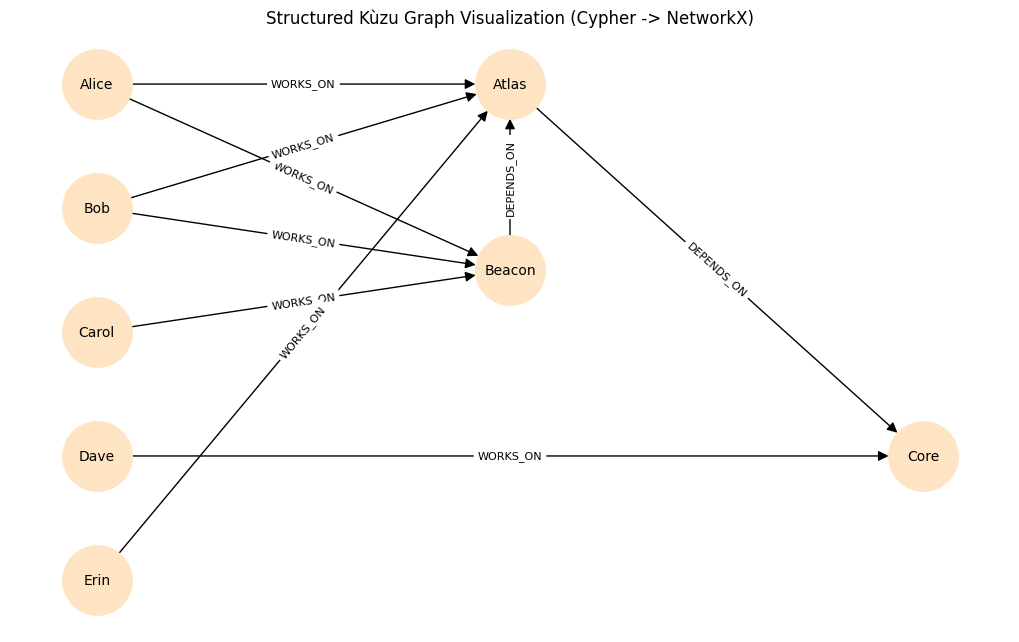

In [ ]:
!pip install -q kuzu==0.11.3
import glob
import os
import kuzu
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# Re-initialize the Kùzu database and helper function to ensure it exists
database_path = "team5_graph.kuzu"
try:
    graph_database = kuzu.Database(database_path)
    connection = kuzu.Connection(graph_database)
except Exception:
    graph_database = kuzu.Database(database_path)
    connection = kuzu.Connection(graph_database)

def run_cypher(cypher_query, query_parameters=None):
    query_result = connection.execute(cypher_query, query_parameters or {})
    return query_result.get_as_df()

def visualize_kuzu_graph():
    results = run_cypher("""
        MATCH (a)-[r]->(b)
        RETURN a.name AS source, label(r) AS rel_type, b.name AS target
    """)

    G = nx.DiGraph()
    for _, row in results.iterrows():
        G.add_edge(row['source'], row['target'], label=row['rel_type'])

    # Use a structured layout matching the first graph (with Erin added)
    pos = {
        "Alice": (0, 3), "Bob": (0, 2), "Carol": (0, 1), "Dave": (0, 0), "Erin": (0, -1),
        "Atlas": (3, 3), "Beacon": (3, 1.5), "Core": (6, 0)
    }
    for node in G.nodes:
        if node not in pos:
            pos[node] = (1, 1.5)

    plt.figure(figsize=(10, 6))
    nx.draw(G, pos, with_labels=True, node_color='bisque', node_size=2500, font_size=10, arrowsize=15)
    edge_labels = nx.get_edge_attributes(G, 'label')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
    plt.title("Structured Kùzu Graph Visualization (Cypher -> NetworkX)")
    plt.axis("off")
    plt.show()

try:
    visualize_kuzu_graph()
except Exception as e:
    print("Could not visualize Kuzu database:", e)

## 7. Questions for the Class
Click each question to reveal the answer.

<details><summary><b>Q1.</b> Is a knowledge graph the same thing as a graph database?</summary>

No. A knowledge graph is the *data* (entities, relationships, and their shared meaning). A graph database is one way to *store and query* it. A KG can also live in an RDF triple store, files, or even relational tables.
</details>

<details><summary><b>Q2.</b> In RDF, how would we record that Alice is the <i>lead</i> on Atlas? Why is this easier in a property graph?</summary>

RDF triples have no place for a property on the edge itself, so we need extra structure (for example a "membership" node with its own role triple, or RDF-star). In a property graph, `role: 'lead'` is simply a property on the `WORKS_ON` relationship.
</details>

<details><summary><b>Q3.</b> In the Cypher query, what goes wrong if we remove <code>WHERE coworker &lt;&gt; alice</code>? What about <code>DISTINCT</code>?</summary>

Without the `WHERE`, Alice matches herself as a coworker on every project. Without `DISTINCT`, Bob appears twice because he shares two projects with Alice.
</details>

<details><summary><b>Q4.</b> The Cypher query needed one pattern, the SQL needed three joins. Does that mean graph databases are always faster?</summary>

No. Performance depends on the workload. Graph databases are good at following relationships (paths, neighborhoods). Relational databases are good at scanning and aggregating structured records. Large traversals in a graph DB can still be expensive.
</details>

<details><summary><b>Q5.</b> Two source systems both say "Alice works on Atlas". How do we avoid storing that fact twice?</summary>

Give entities stable identifiers and use `MERGE` (or an upsert) instead of `CREATE`, so a fact is only added if it is not already there. Keeping a `source` property lets us still track where each fact came from.
</details>

## References
* Hogan, A., et al. (2021). Knowledge graphs. *ACM Computing Surveys*, 54(4), Article 71.
* W3C. (2014). RDF 1.1 concepts and abstract syntax. W3C Recommendation.
* Harris, S., & Seaborne, A. (Eds.). (2013). SPARQL 1.1 query language. W3C Recommendation.
* Neo4j. (n.d.). What is a graph database? and Get started with Cypher. Getting Started documentation.
* rdflib documentation: https://rdflib.readthedocs.io
* Kùzu documentation: https://docs.kuzudb.com